In [3]:
import pandas as pd

# Use the raw URL instead of the blob URL
url = 'https://raw.githubusercontent.com/nivetha486/24ADI204_DSV_Team12/main/Cleaned_Autoimmune_Disorder_Dataset%20(2).csv'

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (12500, 76)


,Patient_ID,Age,Gender,Diagnosis,Sickness_Duration_Months,RBC_Count,Hemoglobin,Hematocrit,MCV,MCH,...,C1_inhibitor,Anti_TIF1,Anti_epidermal_basement_membrane_IgA,Anti_OmpC,pANCA,Anti_tissue_transglutaminase,anti_Scl_70,Anti_Mi2,Anti_parietal_cell,Progesterone_antibodies
0,1,65,Female,Linear IgA disease,26,3.54,13.18,44.35,99.85,31.80,...,0,0,1,0,0,0,0,0,0,0
1,2,61,Male,Dermatomyositis,106,4.97,14.73,42.39,94.86,29.94,...,0,1,0,0,0,0,0,1,0,0
2,3,42,Male,Ord's thyroiditis,6,3.91,13.66,42.41,88.26,29.43,...,0,0,0,0,0,0,0,0,0,0
3,4,45,Female,Restless legs syndrome,11,4.57,14.96,40.10,85.95,27.42,...,0,0,0,0,0,0,0,0,0,0
4,5,78,Female,Autoimmune polyendocrine syndrome type 2 (APS2),30,4.88,11.21,37.58,93.16,29.87,...,0,0,0,0,0,0,0,0,0,0


In [4]:
from sklearn.preprocessing import MinMaxScaler

# Select the 24 numerical measurement columns
columns_to_normalize = [
    'Age', 'Sickness_Duration_Months',
        'RBC_Count', 'Hemoglobin', 'Hematocrit',
            'MCV', 'MCH', 'MCHC', 'RDW',
                'Reticulocyte_Count', 'WBC_Count',
                    'Neutrophils', 'Lymphocytes', 'Monocytes',
                        'Eosinophils', 'Basophils', 'PLT_Count',
                            'MPV', 'Esbach', 'MBL_Level', 'ESR',
                                'C3', 'C4', 'CRP'
                                ]

# Create a copy of the original dataset
df_normalized = df.copy()

# Normalize all selected columns at once
scaler = MinMaxScaler()
df_normalized[columns_to_normalize] = scaler.fit_transform(
                          df[columns_to_normalize]
                                    )

# Display the results
display(df_normalized.head())

# Check the normalized ranges
print(df_normalized[columns_to_normalize].agg(['min', 'max']))

,Patient_ID,Age,Gender,Diagnosis,Sickness_Duration_Months,RBC_Count,Hemoglobin,Hematocrit,MCV,MCH,...,C1_inhibitor,Anti_TIF1,Anti_epidermal_basement_membrane_IgA,Anti_OmpC,pANCA,Anti_tissue_transglutaminase,anti_Scl_70,Anti_Mi2,Anti_parietal_cell,Progesterone_antibodies
0,1,0.712121,Female,Linear IgA disease,0.218487,0.016667,0.424000,0.596429,0.828276,0.966667,...,0,0,1,0,0,0,0,0,0,0
1,2,0.651515,Male,Dermatomyositis,0.890756,0.612500,0.630667,0.456429,0.661887,0.656667,...,0,1,0,0,0,0,0,1,0,0
2,3,0.363636,Male,Ord's thyroiditis,0.050420,0.170833,0.488000,0.457857,0.441814,0.571667,...,0,0,0,0,0,0,0,0,0,0
3,4,0.409091,Female,Restless legs syndrome,0.092437,0.445833,0.661333,0.292857,0.364788,0.236667,...,0,0,0,0,0,0,0,0,0,0
4,5,0.909091,Female,Autoimmune polyendocrine syndrome type 2 (APS2),0.252101,0.575000,0.161333,0.112857,0.605202,0.645000,...,0,0,0,0,0,0,0,0,0,0


     Age  Sickness_Duration_Months  RBC_Count  Hemoglobin  Hematocrit  MCV  \
min  0.0                       0.0        0.0         0.0         0.0  0.0   
max  1.0                       1.0        1.0         1.0         1.0  1.0   

     MCH  MCHC  RDW  Reticulocyte_Count  ...  Eosinophils  Basophils  \
min  0.0   0.0  0.0                 0.0  ...          0.0        0.0   
max  1.0   1.0  1.0                 1.0  ...          1.0        1.0   

     PLT_Count  MPV  Esbach  MBL_Level  ESR   C3   C4  CRP  
min        0.0  0.0     0.0        0.0  0.0  0.0  0.0  0.0  
max        1.0  1.0     1.0        1.0  1.0  1.0  1.0  1.0  

[2 rows x 24 columns]


In [5]:

import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Create a copy of the original dataset
df_encoded = df.copy()

# 1. One-Hot Encoding for Gender
df_encoded = pd.get_dummies(
df_encoded,
columns=['Gender'],
dtype=int
            )

            # 2. Label Encoding for Diagnosis
label_encoder = LabelEncoder()
df_encoded['Diagnosis_Encoded'] = label_encoder.fit_transform(
df_encoded['Diagnosis']
                )

                # Display the result
print("Encoded categorical columns:")
display(df_encoded[['Diagnosis', 'Diagnosis_Encoded']].head())

print("\nGender encoding:")
display(df_encoded.filter(regex='^Gender_').head())

print("\nUpdated dataset shape:", df_encoded.shape)


Encoded categorical columns:


,Diagnosis,Diagnosis_Encoded
0,Linear IgA disease,65
1,Dermatomyositis,31
2,Ord's thyroiditis,81
3,Restless legs syndrome,93
4,Autoimmune polyendocrine syndrome type 2 (APS2),15



Gender encoding:


,Gender_Female,Gender_Male
0,1,0
1,0,1
2,0,1
3,1,0
4,1,0



Updated dataset shape: (12500, 78)


Skewness of numerical features:


,Skewness
C3,-0.102527
Neutrophils,-0.074625
MCHC,-0.067679
MCH,-0.027868
MCV,-0.026598
MPV,0.003635
Lymphocytes,0.013127
Age,0.016029
PLT_Count,0.016357
Reticulocyte_Count,0.027856


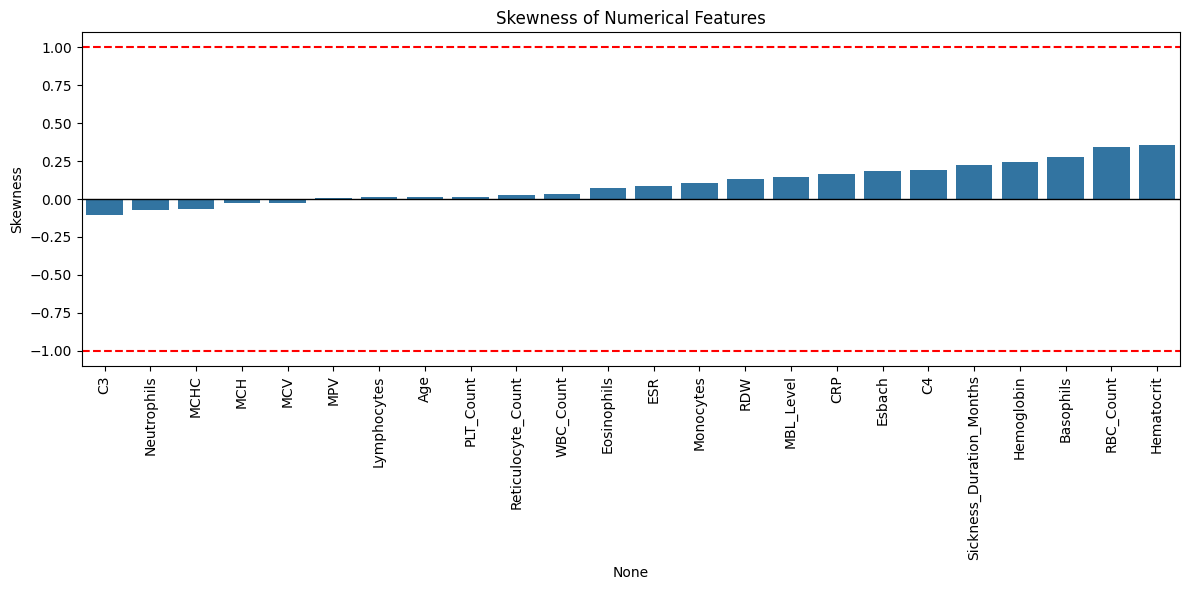

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select continuous numerical columns
numeric_cols = [
    'Age', 'Sickness_Duration_Months',
        'RBC_Count', 'Hemoglobin', 'Hematocrit',
            'MCV', 'MCH', 'MCHC', 'RDW',
                'Reticulocyte_Count', 'WBC_Count',
                    'Neutrophils', 'Lymphocytes', 'Monocytes',
                        'Eosinophils', 'Basophils', 'PLT_Count',
                            'MPV', 'Esbach', 'MBL_Level', 'ESR',
                                'C3', 'C4', 'CRP'
                                ]

                                # Calculate skewness using original data
skew_values = df[numeric_cols].skew().sort_values()
print("Skewness of numerical features:")
display(skew_values.to_frame(name="Skewness"))

                                # Visualize the skewness of each feature
plt.figure(figsize=(12, 6))
sns.barplot(x=skew_values.index, y=skew_values.values)
plt.axhline(0, color='black', linewidth=1)
plt.axhline(1, color='red', linestyle='--')
plt.axhline(-1, color='red', linestyle='--')
plt.xticks(rotation=90)
plt.ylabel("Skewness")
plt.title("Skewness of Numerical Features")
plt.tight_layout()
plt.show()


In [7]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from google.colab import files

# Start with the original dataset
df_final = df.copy()

# Normalize numerical columns
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df_final[columns_to_normalize] = scaler.fit_transform(df[columns_to_normalize])

# Add gender dummy columns
gender_dummies = pd.get_dummies(
    df_final['Gender'], prefix='Gender', dtype=int
    )
df_final = pd.concat([df_final, gender_dummies], axis=1)

    # Encode diagnosis
le = LabelEncoder()
df_final['Diagnosis_Encoded'] = le.fit_transform(df_final['Diagnosis'])

    # Save and download the dataset
output_file = '/content/Week6_Feature_Engineered_Dataset.csv'
df_final.to_csv(output_file, index=False)
files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>